# Notebook 05 — Reinforcement learning: letting the robot practise

So far the robot learned by **imitation**: it copied the scripted driver. Notebook 04's tests showed what is still
weak, typically:

1. **Goals that start out of view.** In ordinary rooms the car finds a hidden goal only about 60% of the time, a
   visible one 80–90%. Almost every failed drive ends with the goal out of view: the car has no memory, so once it
   turns away from something it has forgotten it.
2. **Getting stuck on obstacles.** About half of the test drives touch an obstacle or a wall, and in a third to two
   thirds of the failed drives the car spent 10 s or more pressed against something.
3. **Lookalikes.** Two objects of the same colour are still often confused in the words test (this one is mostly
   about reading, which RL doesn't practise directly).

Why imitation alone can't fix these: the robot only ever saw **good drives**. When it makes a small mistake it ends
up somewhere it never saw in training, and the mistake grows ("compounding errors", Ross et al. 2011).

**Reinforcement learning (RL)** lets the robot **practise**. It drives thousands of times in the simulator, gets a
**score** for each drive, and slowly shifts towards what scored well. It experiences its own mistakes and their cost,
which imitation never showed it.

**The setup**

| Choice | What we use |
|---|---|
| Start from | a **notebook 04** model (choose the head in section 1), not from scratch |
| Action head | its flow-matching head, with 4 refining steps |
| Algorithm | PPO with ReinFlow-style jitter, so action probabilities can be computed |
| Score | map-based progress, success bonus, time cost, crash penalty, a sight term that makes losing the goal cost |
| Keep the old skills | a "practise the demos" (imitation) lesson mixed into every update |
| Simulators | 8 in parallel, physics on the CPU |
| What learns | the action head, the jitter size and a new critic; the reader stays locked (memory) |

**What you will learn here**
1. How a reward is designed, and how robots cheat badly designed ones.
2. Why we run the simulators on the CPU.
3. Why a flow-matching head needs a trick before PPO can train it.
4. How PPO works: advantages, the critic, clipping, and the KL guard.
5. How to read RL training graphs, and the warning signs to look for.

**Time and hardware:** about 2 minutes per round on an RTX 4080 SUPER + 20-core CPU; the recommended run is 100
rounds, about 3.5–4 hours. Only one run fits on a 16 GB GPU at a time; a second run (another seed or head) goes after it. RL needs about 10 GB of GPU memory. On a Mac it runs, but expect it to be many times slower.

## 1. Setup

**Choose the starting model** with `HEAD`: `"car"` (the car head) or `"smolvla"` (smolVLA's arm-pretrained head),
both trained in notebook 04. Either works; pick the one that tested better there, or try both one after the other.

**Close other notebooks first.** Training needs about 9.5 GB of GPU memory, and the 8 simulators need
another ~2.2 GB to draw their camera images. On a 16 GB card, every other notebook kernel that holds a
model can cause an *out of memory* crash. Use *Kernel → Shut Down Kernel* in your other notebooks.
On an NVIDIA GPU, the cell below shows what is using it right now.

`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` is set **before** importing torch. Without it,
GPU memory gets fragmented (we measured 3.4 GB reserved but unusable) and training crashed.

In [2]:
import os, sys, json, time, shutil, subprocess
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # must happen before torch is imported
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"

HEAD = "car"                                                          # "car" or "smolvla" (notebook 04)
PREP = RUNS / "datasets" / "scripted_close_prep.json"                 # notebook 03 (for the "practise the demos" lesson)
START_CHECKPOINT = RUNS / "checkpoints" / f"bc_{HEAD}_head.pt"         # notebook 04
assert START_CHECKPOINT.exists(), "Run notebook 04 first: it trains the model RL starts from."

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

from carsim.device import pick_device, describe
from carsim.rl_env import RewardConfig
from carsim.ppo import PPOConfig, PPOTrainer, plot_progress
DEVICE = pick_device()
print(describe())
if DEVICE == "cuda" and shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "--query-gpu=memory.used,memory.total", "--format=csv"], capture_output=True, text=True).stdout)
    print("Programs using the GPU (pid, MB):")
    print(subprocess.run(["nvidia-smi", "--query-compute-apps=pid,used_memory", "--format=csv,noheader"], capture_output=True, text=True).stdout)

device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1
memory.used [MiB], memory.total [MiB]
803 MiB, 16376 MiB

Programs using the GPU (pid, MB):
1708, 55 MiB



## 2. The score (reward)

After every 0.1 s step the simulator gives the robot points. The robot learns to collect as many
points as it can over a drive.

| Part | Rule | What it teaches |
|---|---|---|
| **Progress** | **+1 per metre** closer to the goal along the shortest path around obstacles (−1 per metre farther) | the main teacher: gives a hint at every step, even when the goal is hidden ("warmer / colder") |
| **Success** | **+2.5** for arriving and stopping at the right object | finish the job, and stop there |
| **Time** | **−0.01 per step** | don't dawdle |
| **Crash** | **−0.1 per step** spent touching anything except the goal | don't hit things |
| **Sight** | **+0.2** when the goal comes into view, **−0.3** when it leaves the picture | find the goal, and don't lose sight of it: every loss costs 0.1 net, even if it's found again |

**How robots cheat a reward, and how we prevent it.** An RL robot doesn't know what you *meant*, only
what scores. Some classic traps:

* *"Points while the goal is visible"* → the robot learns to stare at the goal without driving to it.
  Our sight term instead scores the **change**: gaining sight +0.2, losing it −0.3. Looking away and back
  costs 0.1, so it can never be farmed. (With −0.2 it would cancel out exactly. We make losing sight cost a
  little on purpose: the imitation model's failed drives almost always end with the goal out of view.)
* *"Points for moving closer"* without a matching penalty for moving away → drive back and forth.
  Our progress term is also a change (old distance − new distance), so over a drive it always adds up
  to *start distance − end distance*. This "potential-based shaping" is proven not to change what the
  best behaviour is (Ng et al. 1999). The sight term is *not* fully potential-based any more (the −0.1 net per
  loss): it deliberately prefers drives that keep the goal in view.
* *"End the episode early if stuck"* → if the rest of the drive would score badly anyway, the robot
  learns to get stuck on purpose. So drives end only on success or at the 60 s limit.

**About the map.** "Distance along the shortest path" comes from the simulator's map. Only the
**scorer** uses it, during practice. The robot itself never sees the map: it drives from the camera
and the instruction alone.

The check below runs a few drives each with the autopilot, standing still, and random driving. A sensible
reward must rank them **autopilot ≫ standing still > random**. It runs in a separate process so its
simulator's memory is freed afterwards.

In [3]:
print(subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "rl_reward_check.py"), "8"], capture_output=True, text=True).stdout)

autopilot    score per drive    5.12   success 100%   progress +3.32  success +2.50  time -0.74  crash +0.00  sight +0.20  sight_lost -0.15
stand still  score per drive   -6.00   success   0%   progress +0.00  success +0.00  time -6.00  crash +0.00  sight +0.00  sight_lost +0.00
random       score per drive  -37.56   success   0%   progress -0.22  success +0.00  time -6.00  crash -31.06  sight +0.25  sight_lost -0.52



**What you should see** (our check, 8 drives each; the reward parts are listed per drive): the autopilot about
**+5.1** per drive with 100% success; standing still exactly **−6.0** (600 steps × −0.01, all time cost); random driving about **−38**, almost all crash penalty.

**One thing to keep in mind.** Random driving scores far *worse* than standing still. A robot that
became very unsure could discover that "don't move" is the safe choice. Starting from the imitation
model protects against that, because it already drives purposefully. If the success rate ever drops
while "drives with a crash" also drops sharply, that's this trap.

## 3. The practice arena: 8 simulators on the CPU

RL needs a lot of practice, so simulator speed matters. We measured, on a 20-core CPU (see the docstring of
`carsim/rl_env.py`):

| Setup | Control steps per second |
|---|---|
| 1 simulator, physics on the GPU | 80 |
| 2–4 simulators on the GPU | ~67 **in total**: they queue for the same GPU |
| 1 simulator, physics on the **CPU** | 150 |
| 6 simulators on the CPU | ~730 in total |
| 8 / 16 simulators on the CPU (in the RL arena) | ~785 / ~900 in total |

Our scene is small, so the GPU spends most of its time on overhead, while the 20 CPU cores can each run
their own copy. CPU and GPU physics give **identical** results: same positions, same collisions, same
images.

Each simulator still uses the GPU to **draw** its camera image (~280 MB each). That's why we use 8 and
not 16: 16 is only ~15% faster but costs 2.2 GB more GPU memory than we can spare.

Each simulator lives in its own process (`ParallelNav`). Every **decision** of the robot is a chunk of 10
planned actions, of which the first **5 are driven** (0.5 s) before it looks again. When a drive ends, that
simulator immediately starts a new random layout with a new random goal and a reworded instruction. The
held-out **orange sphere** is never a goal during practice: it stays our test of generalisation.

## 4. Making the flow-matching head trainable by PPO

**How the head makes an action.** The action head works like a sculptor. It starts from random
noise and refines it in a few small steps into a clean chunk of actions:

$$x \leftarrow x + \Delta t \cdot v(x, t) \qquad \text{(4 steps, } t = 1 \to 0\text{)}$$

**The problem.** PPO works by making good actions **more likely** and bad ones **less likely**, so it
needs the number "how likely was this action?". With purely deterministic refining steps, nobody can
easily compute that.

**The fix (ReinFlow, Zhang et al. 2025; Flow-Noise in πRL).** Add a small, known jitter at each step:

$$x \leftarrow x + \Delta t \cdot v(x, t) + \sigma \cdot \text{noise}$$

Each jittered step is a bell curve around the deterministic step, and a bell curve's probability has a
simple formula. Multiply the 4 steps together and you get the probability of the whole action. The
jitter is also how the robot **explores**: it tries slightly different actions. σ (the jitter size) is
learned, separately for forward/sideways/turning, and kept between 0.02 and 0.2 (in units of "fraction
of maximum speed").

Only the numbers that are actually driven get jitter: the first 5 actions of the chunk.

**What we measured before building the training loop** (on an earlier imitation model)
* With **4 refining steps** instead of 10, the imitation model drives just as well (59% vs 58% success
  over 64 drives each), so we use 4. That makes training ~2.5× cheaper.
* With jitter σ = 0.08 it still drives about the same (56%).
* Re-scoring the same action gives **exactly** the same probability (difference 0.0), but only at full
  precision. In the faster bf16 arithmetic, the same sample gave slightly different numbers depending
  on which batch it was in. PPO saw that as fake policy change (KL 0.012 with no learning at all). So
  everything runs in fp32.

Creating the trainer below loads the model, starts the 8 simulators (~15 s) and loads the scripted demos for
the imitation lesson.

## 5. How PPO learns, one round at a time

```
 ┌─► 1. COLLECT  8 simulators × 256 decisions = 2048 decisions (~50 s)
 │      store: what it saw, the jittered chain it used, how likely that was,
 │             the critic's guess, the reward it got
 │   2. ADVANTAGES  "how much better than the critic expected?" for every decision
 │   3. LEARN  2 passes over the batch, mini-batches of 32 (~25 s)
 │      • PPO loss: better-than-expected → more likely; worse → less likely,
 │                  but each change is CLIPPED (ratio limited to 1 ± 0.2)
 │      • critic loss: predict the scores that actually happened
 │      • imitation loss on the demos ("keep practising the demos")
 │      • KL guard: if the policy already moved too far, skip the rest of this round
 └── every 10 rounds: fixed test set (32 drives, same layouts every time, NO jitter) + save
```

**The critic (value head).** A small network on top of the locked reader's notes. It looks at the
picture and instruction and predicts the score the robot will probably get from here on. Without it,
the robot can't tell a good decision from a lucky one. "Advantage" = what actually happened − what the
critic expected. We use **GAE** (Schulman et al. 2016), which blends "what happened next" with "what the
critic expects after that", trading noise against bias.

**Critic warm-up.** The critic starts out random. In the first 5 rounds only the critic learns and the
driving stays exactly as it is, so the first real updates aren't steered by nonsense.

**Why updates must be small.** The probability of an action is a product of 60 bell curves (5 actions ×
3 numbers × 4 steps), so tiny changes in the model change it a lot. We measured one step at the usual
fine-tuning learning rate (1e-5): the policy moved ~60× too far (KL 1.4). At **1e-6** a step is a
healthy size (KL ≈ 0.01). The KL guard (`target_kl = 0.05`) is the safety net on top.

**Keeping the old skills.** The imitation loss starts at weight 1.0 and is lowered to 0.1 over 100 rounds, so
RL can gradually improve on the demonstrated driving without forgetting it (the idea comes from DAPG, Rajeswaran et
al. 2018).

**Discounting.** γ = 0.995 per 0.1 s step: a point 20 s in the future counts about 37% as much as a point
now. This makes the robot prefer quicker success.

### 5.1 What the robot practises on

Practice and testing use **different layouts on purpose**:

| Setting | Practice | Test | Why |
|---|---|---|---|
| goal in view at the start | **1 in 4** drives | 1 in 2 (the standard rooms) | practise the case that fails most: in notebook 04's tests the car found a hidden goal only about 60% of the time, a visible one 80–90% |
| a lookalike object in the room | 1 in 2 drives | 1 in 2 | lookalikes were not a big cause of failures in ordinary rooms, so practice time goes to searching and obstacles |
| decisions per simulator per round | 256 | | enough finished drives per round for a clear lesson (with 128, each round's lesson was blurry: only ~13 drives finished) |

So **expect the *practice* success line to sit lower than the *test* dots**: practice is harder on purpose. Judge
progress by the **test** dots, especially "goal hidden at start".

In the "size of each update" graph, **share of study done before KL stop** shows how much of each round's planned
learning happened: 1.0 means all of it; a low value means the KL guard stopped it early.

All these settings, with comments, are in `PPOConfig` (`carsim/ppo.py`):

In [4]:
cfg = PPOConfig()          # every setting, with comments, is in carsim/ppo.py
RUN_DIR = RUNS / "rl" / time.strftime("ppo_%Y%m%d_%H%M")
for k, v in vars(cfg).items():
    print(f"{k:24s} {v}")

n_envs                   8
decisions_per_round      256
practice_layout          {'p_goal_visible': 0.25, 'p_hard_distractor': 0.5}
exec_steps               5
denoise_steps            4
gamma                    0.995
gae_lambda               0.95
epochs                   2
minibatch                32
micro_batch              16
clip                     0.2
target_kl                0.05
actor_lr                 1e-06
critic_lr                0.0003
sigma_lr                 0.001
sigma_init               0.08
sigma_min                0.02
sigma_max                0.2
max_grad_norm            1.0
critic_warmup_rounds     5
bc_batch                 16
bc_mirror_p              0.0
bc_coef_start            1.0
bc_coef_end              0.1
bc_decay_rounds          100
eval_every               10
eval_episodes_per_env    4
eval_seed                999
seed                     0
full_precision           True
reward                   RewardConfig(progress=1.0, success=2.5, time=-0.01, crash=-0.1

In [5]:
tr = PPOTrainer(cfg, START_CHECKPOINT, RUN_DIR, PREP, device=DEVICE)
print("run folder:", RUN_DIR, "| starting from", START_CHECKPOINT.name)

/home/mayur/Projects/obstacle_avoidance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 489/489 [00:00<00:00, 5136.85it/s]


Reducing the number of VLM layers to 16 ...


run folder: /home/mayur/Projects/obstacle_avoidance/runs/rl/ppo_20261113_1842 | starting from bc_car_head.pt


**Look inside one decision.** The robot picks actions for all 8 simulators at once. For each one we get
the 5 actions it will drive, the probability of the jittered chain (as a log-probability: a big
negative-or-positive number, because it is a *density* over 60 numbers; only *changes* in it matter),
and the critic's guess. Re-scoring the same chains must give the same log-probability, up to tiny rounding differences (we see about
0.00001; anything above about 0.01 would show up as fake policy change in PPO).

instruction: Your goal: the orange pillar.
first 5 actions (vx m/s, vy m/s, wz rad/s):
 [[-0.05  0.03  0.93]
 [ 0.03 -0.04  0.92]
 [ 0.33  0.03 -1.31]
 [ 0.71 -0.02 -0.34]
 [ 0.67  0.03 -0.32]]
log-probability at acting: [68.54 66.3  62.42 62.97]
re-scored               : [68.54 66.3  62.42 62.97]
largest difference      : 7.62939453125e-06
critic's guess (untrained yet): [-0.04  0.04 -0.   -0.04]


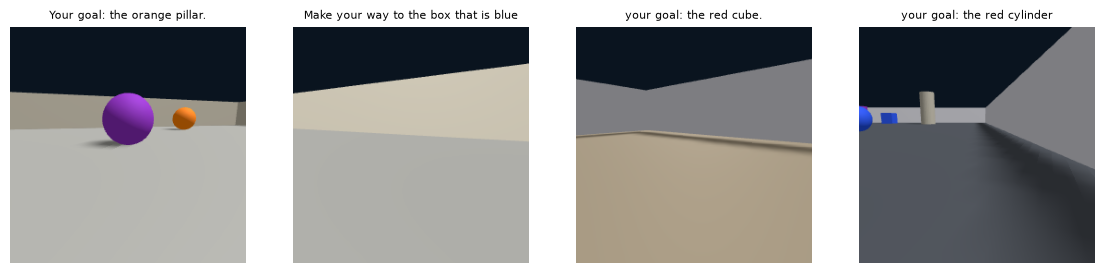

In [6]:
imgs, states, prompts = tr.obs
a = tr.rl.act(imgs, prompts, states)
with torch.no_grad():  # just looking: no learning graph kept in memory
    lp, v = tr.rl.evaluate(imgs, prompts, states, a["chain"])
print("instruction:", prompts[0])
print("first 5 actions (vx m/s, vy m/s, wz rad/s):\n", a["actions"][0].round(2))
print("log-probability at acting:", a["logp"][:4].numpy().round(2))
print("re-scored               :", lp[:4].detach().cpu().numpy().round(2))
print("largest difference      :", float((lp.detach().cpu() - a["logp"]).abs().max()))
print("critic's guess (untrained yet):", a["value"][:4].numpy().round(2))
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for i in range(4):
    ax[i].imshow(imgs[i]); ax[i].set_title(prompts[i], fontsize=8); ax[i].axis("off")
plt.show()

## 6. The starting line

Before any RL, the fixed test set: 32 drives (4 per simulator, the same layouts every time), **no
jitter**. Counting exactly 4 drives per simulator matters. If we counted "the first 32 drives to
finish", quick successes would finish first and make the robot look better than it is.

(Two minutes or so. Failed drives last the full 60 s.)

In [7]:
t0 = time.time()
start = tr.evaluate()
print(json.dumps({k: round(v, 3) if isinstance(v, float) else v for k, v in start.items()}, indent=1), f"\n{time.time()-t0:.0f}s")

{
 "round": 0,
 "tag": "standard",
 "n": 32,
 "success": 0.719,
 "success_visible_start": 0.792,
 "success_hidden_start": 0.5,
 "crash_episodes": 0.594,
 "return": -3.141,
 "seconds": 25.15
} 
67s


## 7. Train

Each round takes about 2 minutes, plus a 2-minute quick test every 10 rounds: roughly **27 rounds per hour**. The
cell runs **100 rounds (about 3.5–4 hours)**. Why 100: the "practise the demos" lesson fades from full weight to its
final low weight over the first 100 rounds (`bc_decay_rounds`), so RL only gets its full freedom to change the driving
towards the end of that; and the first 5 rounds only train the critic. Expect "drives with a crash" to improve first;
"goal hidden at start" success, if it improves, usually needs longer. The graphs redraw after every round. **Stop any time** with the ■ (interrupt) button: the
run is saved, and the cell in section 8 continues it.

**How to read the graphs**

| Graph | Healthy | Warning sign |
|---|---|---|
| **Success rate** | the test-set dots (no jitter) rise over tens of rounds | falling for many rounds in a row |
| **Score per drive** | rising | falling |
| **Drives with a crash** | falling | falling *together with* success → the "don't move" trap |
| **Critic accuracy** | rises from ~0 during warm-up, then 0.3–0.8 | stays near 0 or negative → advantages are noise |
| **Size of each update** | KL below 0.05, fraction clipped below ~0.3, study done near 1.0 | study done very low every round → the KL guard cuts almost all learning |
| **Jitter σ** | slowly shrinks as the robot gets more sure | collapses to the 0.02 floor early → exploration has stopped |

**Be patient and sceptical.** RL curves are noisy. The practice line includes jitter, covers only the last
100 drives, and uses harder layouts than the test (section 5.1). Trust trends over tens of rounds, and trust the
test-set dots more than the practice line. 32 test drives is still small: differences under about ±15 points
can be luck. Section 9 measures the result properly, on the full tests of notebook 04.

The first 5 rounds are critic warm-up: the driving doesn't change yet.

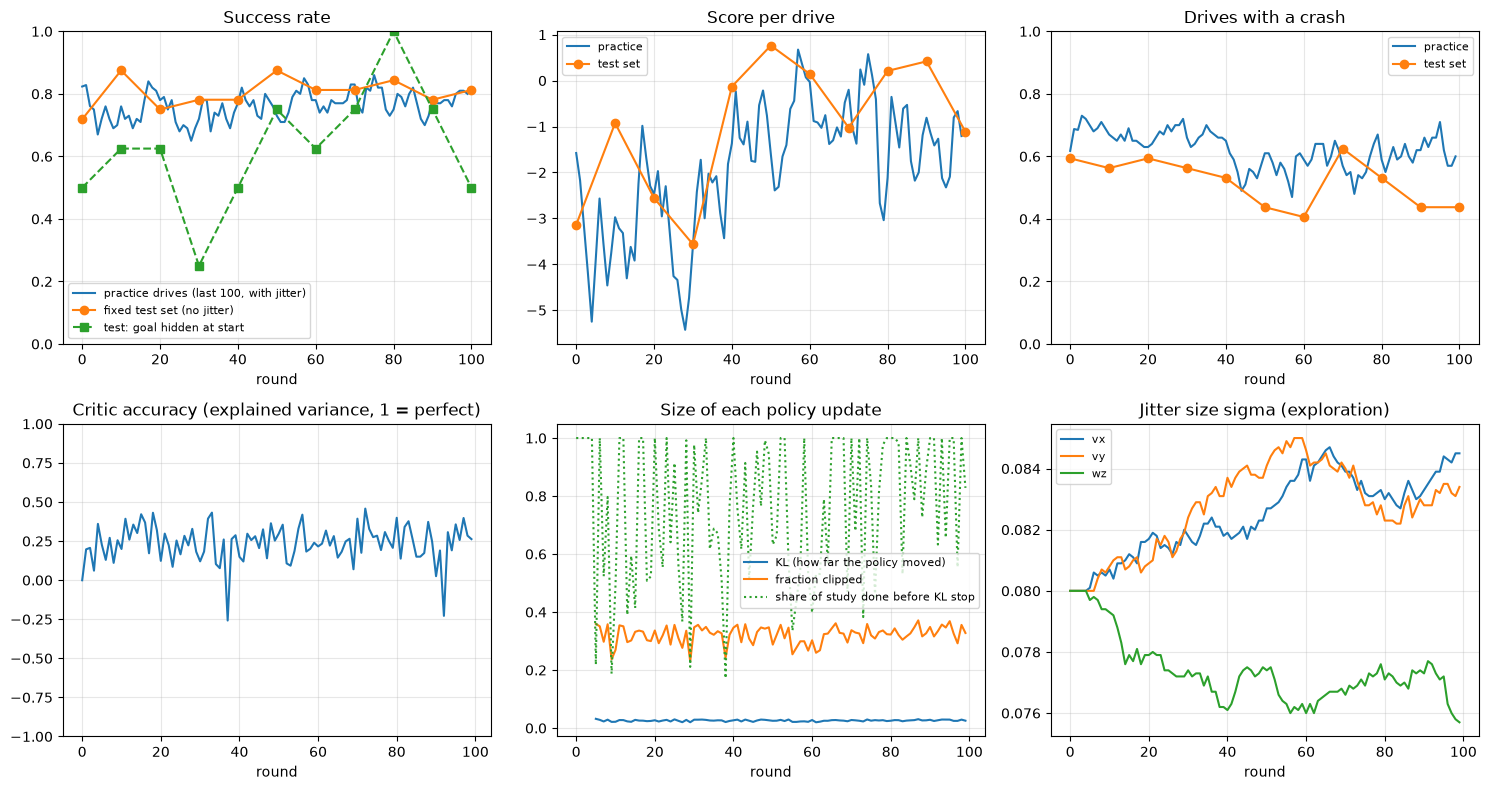

round   99  practice success 80%  score  -1.21  crash 60%  critic +0.26  KL 0.025  study done 83%  sigma [0.08449999988079071, 0.08340000361204147, 0.07569999992847443]  (49+88s) | TEST success 81% (round 100)
saved: /home/mayur/Projects/obstacle_avoidance/runs/rl/ppo_20261113_1842/latest.pt


In [8]:
N_ROUNDS = 100  # ~3.5-4 hours (~2 min per round + a quick test every 10 rounds); stop any time with ■, run again to continue
fig = plt.figure(figsize=(15, 8))
try:
    for _ in range(N_ROUNDS):
        e = tr.train_round()
        plot_progress(tr, fig)
        clear_output(wait=True)
        display(fig)
        ev = f" | TEST success {tr.evals[-1]['success']:.0%} (round {tr.evals[-1]['round']})" if tr.evals else ""
        print(f"round {e['round']:4d}  practice success {e['success_last100'] or 0:.0%}  score {e['return_last100'] or 0:6.2f}  "
              f"crash {e['crash_episodes_last100'] or 0:.0%}  critic {e['explained_variance']:+.2f}  "
              f"KL {e['kl'] if e['kl'] is not None else float('nan'):.3f}  study done {e['study_done']:.0%}  sigma {e['sigma']}  "
              f"({e['collect_s']:.0f}+{e['learn_s']:.0f}s){ev}")
except KeyboardInterrupt:
    print("Stopped by you.")
finally:
    tr.save("latest")
    print("saved:", RUN_DIR / "latest.pt")
plt.close(fig)

## 8. Continue a run (after a pause, or in a new session)

If the kernel is still running, simply run the training cell (section 7) again: the trainer keeps its
state.

After a restart: run section 1, the two cells of section 5 with `RUN_DIR` set to the old folder, then the
cell below. It restores the policy, critic, jitter size, optimizer and all graphs from `latest.pt`.

In [9]:
# RUN_DIR = RUNS / "rl" / "ppo_YYYYMMDD_HHMM"   # <- set this if you restarted the kernel
# tr = PPOTrainer(cfg, START_CHECKPOINT, RUN_DIR, PREP, device=DEVICE)
if (RUN_DIR / "latest.pt").exists():
    tr.load(RUN_DIR / "latest.pt")
    print("continuing from round", tr.round)

continuing from round 100


## 9. Compare with the starting line

### 9.1 The quick check

The fixed practice-test set again, with more drives (8 per simulator = 64) for a tighter comparison. `best.pt` holds
the policy with the best test-set score so far.

In [10]:
final = tr.evaluate(episodes_per_env=8)
for k in ("success", "success_visible_start", "success_hidden_start", "crash_episodes", "return", "seconds"):
    print(f"{k:24s} start {start[k]:7.3f}   now {final[k]:7.3f}")

success                  start   0.719   now   0.797
success_visible_start    start   0.792   now   0.821
success_hidden_start     start   0.500   now   0.760
crash_episodes           start   0.594   now   0.391
return                   start  -3.141   now  -0.567
seconds                  start  25.150   now  23.625


### 9.2 Shut down the practice arena

Stops the 8 simulator processes and frees their memory (and the GPU memory of the trainer) before the full tests.

In [11]:
tr.close()
del tr; import gc; gc.collect()
from carsim.device import empty_cache; empty_cache(DEVICE)

### 9.3 The full tests: RL vs imitation

The same words test and standard test as notebook 04, on exactly the same drives, so the RL policy (`best.pt`, or `latest.pt` before the first test round) and
its imitation starting point can be compared drive by drive. About 10 minutes.

which (282 s): done
standard (211 s): done


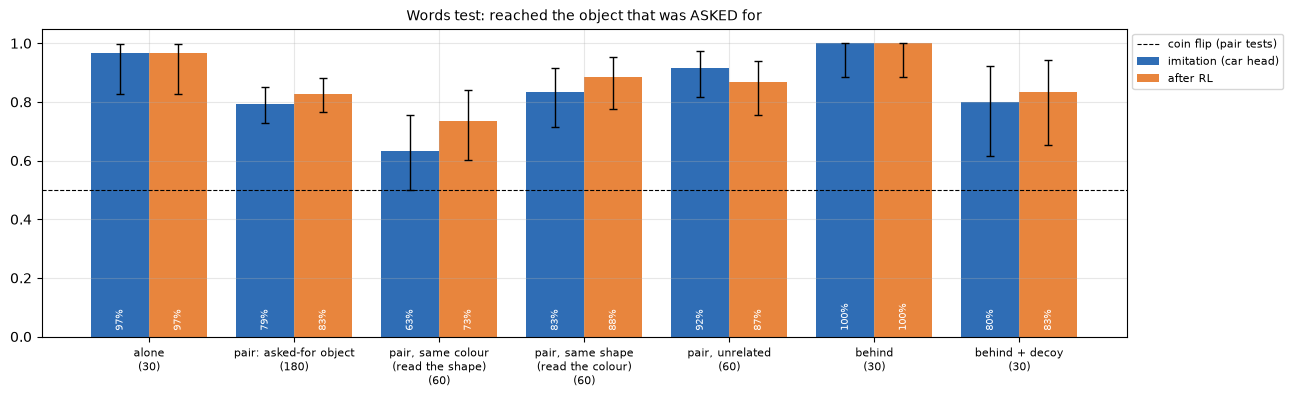

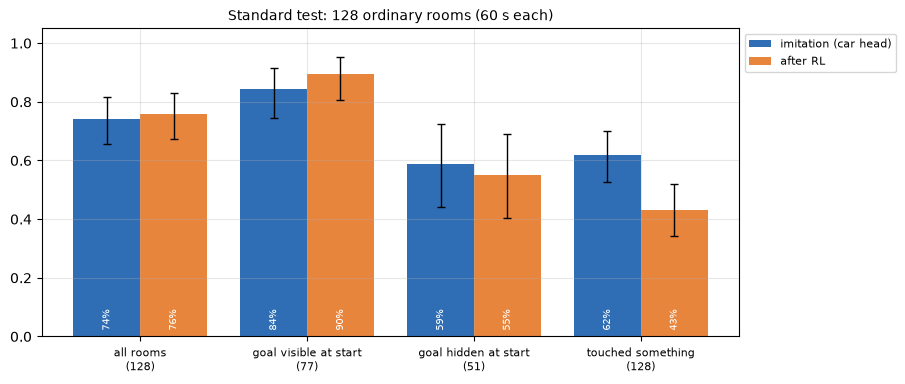

pair drives (asked-for object): imitation 79% vs RL 83% | only imitation right: 17, only RL right: 23 | p = 0.430 (could easily be luck)
standard rooms: imitation 74% vs RL 76% | only imitation right: 11, only RL right: 13 | p = 0.839 (could easily be luck)


,imitation (car head),after RL
success: all rooms,74%,76%
success: goal visible at start,84%,90%
success: goal hidden at start,59%,55%
drives that touched something,62%,43%
seconds touching per drive (mean),5.0,1.9
failed drives,33 of 128,31 of 128
... stuck: 10 s or more touching,16,1
... goal out of view at the end,28,28
"seconds to reach the goal (median, successes)",9.8,9.3


In [12]:
from carsim import evaluate as ev
SCORECARDS = RUNS / "rl" / "scorecards"; DIAGNOSIS = RUNS / "diagnosis"
RL_TAG = f"rl_{RUN_DIR.name}_{HEAD}"
RL_CKPT = RUN_DIR / "best.pt" if (RUN_DIR / "best.pt").exists() else RUN_DIR / "latest.pt"   # best.pt appears at the first test (round 10)
START_TAG = f"nb04_bc_{HEAD}_head"                     # notebook 04 already tested the starting model
for test in ("which", "standard"):
    extra = ["--detail", str(DIAGNOSIS / f"{RL_TAG}_{test}_detail.json")]          # every drive's path, for the maps below
    t0 = time.time()
    r = subprocess.run([sys.executable, "scripts/rl_tests.py", test, "--bc", str(START_CHECKPOINT), "--ckpt", str(RL_CKPT),
                        "--out", str(SCORECARDS / f"{RL_TAG}_{test}.json")] + extra, cwd=PROJECT_ROOT, capture_output=True, text=True)
    print(test, f"({time.time() - t0:.0f} s):", "done" if "SUMMARY" in r.stdout else r.stdout[-2000:] + r.stderr[-2000:])
MODELS = {f"imitation ({HEAD} head)": START_TAG, "after RL": RL_TAG}
ev.words_chart(MODELS); plt.show()
ev.standard_chart(MODELS); plt.show()
for test in ("which", "standard"):
    print(ev.paired(START_TAG, RL_TAG, test, "imitation", "RL"))
ev.failure_table(MODELS)

**How to read it.** The first charts and the luck test are the same as notebook 04, section 9. The table at the end
breaks the standard test down into the two weaknesses RL practises:

| Row | RL should… |
|---|---|
| success: goal hidden at start | go **up** (searching) |
| drives that touched something, seconds touching per drive, stuck 10 s or more | go **down** (not bumping) |
| failed drives with the goal out of view at the end | go **down** (not losing the goal) |
| pair: asked-for object (words test) | stay about the **same**: RL should not trade reading for driving |

A rise or fall of a few points with p above 0.05 can be luck; train for more rounds before drawing conclusions. If
the words-test pair score *drops*, RL is trading reading for driving: keep the imitation lesson's weight higher
(`bc_coef_end` in `PPOConfig`).

### 9.4 How did the failed drives fail, before and after RL?

Every failed drive in the standard test is a 60 s timeout. From each drive's path we sort the failures into one group
each (`carsim.evaluate.failure_kinds`):

| Group | Meaning | What RL should do to it |
|---|---|---|
| **stuck on an obstacle** | 10 s or more touching an obstacle or a wall | shrink: the crash cost teaches it to back off |
| **parked at another object** | ended next to an object that isn't the goal | shrink |
| **never saw the goal** | the goal was never in the picture | shrink: practice starts with the goal hidden in 3 of 4 drives |
| **saw it, then lost it** | had the goal in the picture, then lost it | shrink: losing sight now costs 0.1 net |
| **goal in view at the end** | still had it in view when time ran out | usually small |

Then maps of failed drives after RL: blue = driven path, red dots = touching something, red dotted = the shortest
path, white star = the goal. Compare with the same maps for the imitation model in notebook 04, section 9.5.

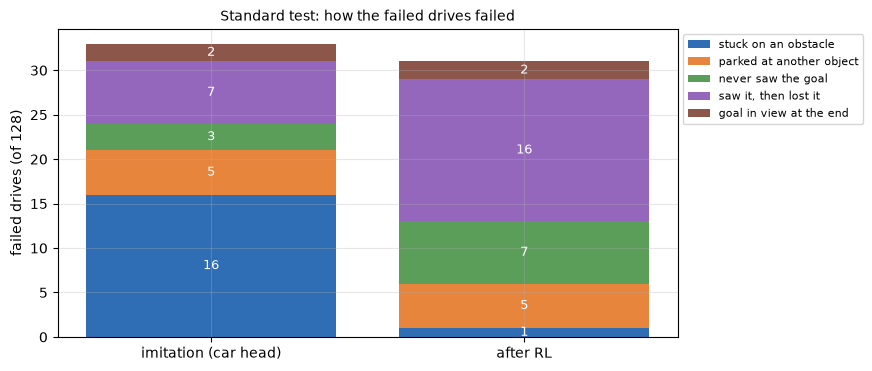

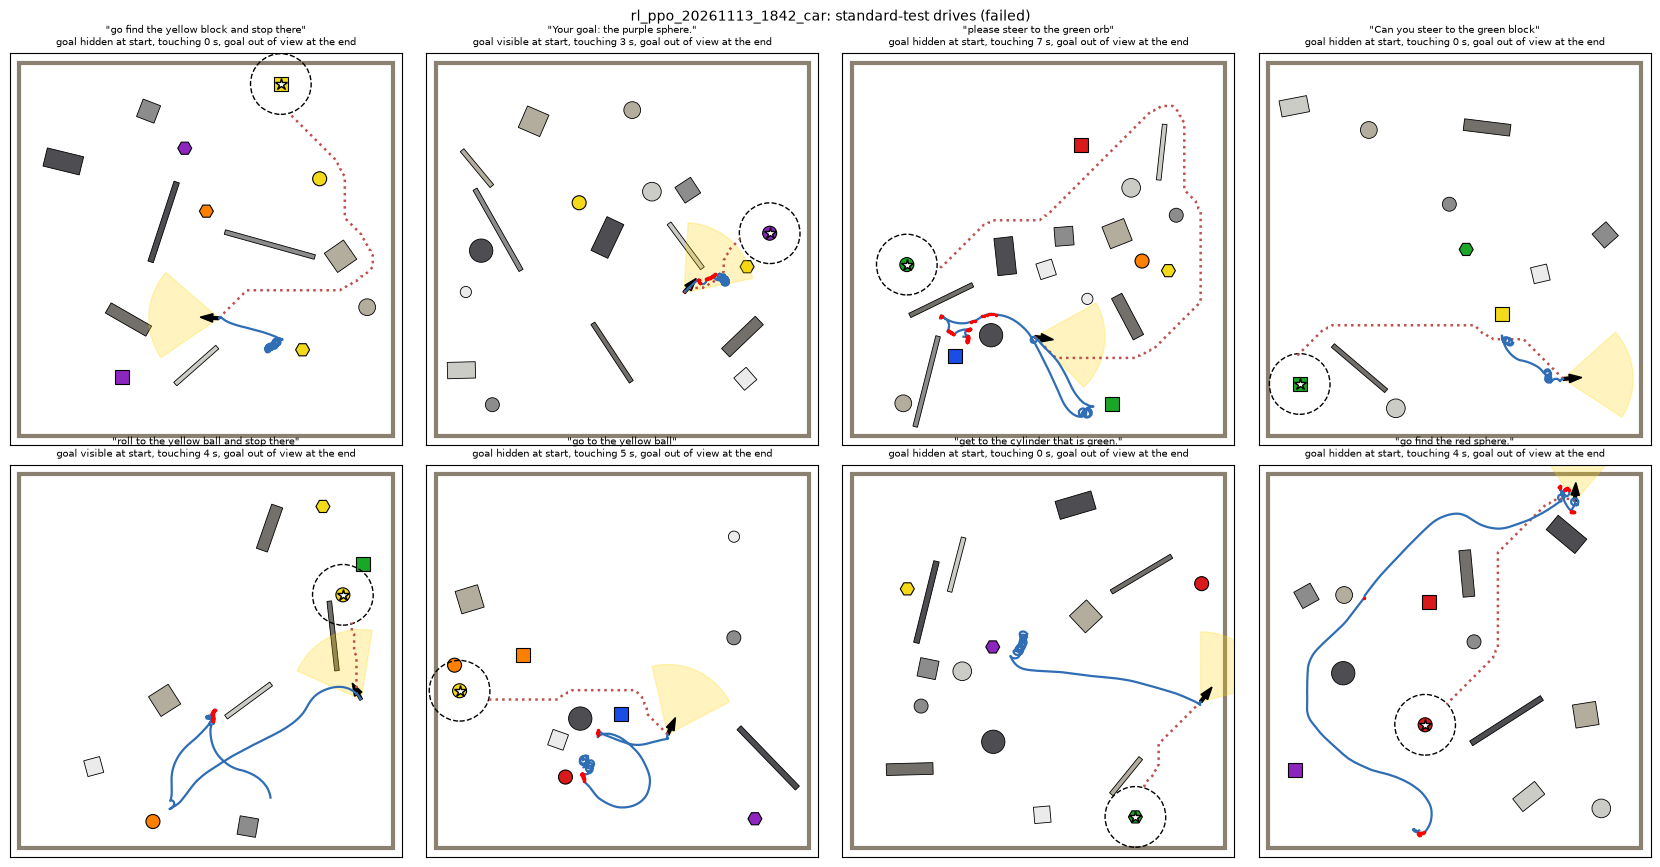

In [13]:
ev.failure_kinds_chart(MODELS); plt.show()
ev.plot_room_drives(RL_TAG, only="failed", n=8); plt.show()

### 9.5 Watch it drive

The car after practice (`best.pt`, loaded on top of notebook 04's car) drives one room in Genesis.

The video shows two views side by side. **Left:** the overhead camera (shown for you; this car never sees it). Blue = where the car has driven.
**Right:** the car's front camera, the only picture its own model sees. The text on top shows the time and whether the
car is touching something. The video plays at 2× speed.

**Settings:** `ROOM` = any layout seed (try others: every seed is a different room); `LIVE = True` also opens the
Genesis 3-D window with a chase camera and drives at real-time speed (needs a screen; the window closes when the drive
ends); `FORCE = True` drives again instead of reusing the saved video (in `runs/videos/`).

**One drive is an example, not a test.** The default room was picked to show the difference between the notebooks'
cars (it comes from the standard test, and the front-camera cars of notebooks 04 and 05 fail it). The success rates are
the tests above. A single drive can also differ from the same room in the test: the test words the instruction
differently (e.g. "move to" vs "head over to"), and small changes add up over a minute of driving.

**What you should see:** In the default room the goal is hidden behind a long wall at the start. Practice made this car bump less (about 3 s of touching instead of notebook 04's 13 s in this room), but it still can't find the goal and runs out of time. That is notebook 05's result in one drive: less bumping, no better searching.

In [ ]:
from carsim.viz import watch_drive
ROOM, LIVE, FORCE = 623600484, False, False
watch_drive(START_CHECKPOINT, RL_CKPT, room=ROOM, name="nb05_ppo_car", title="notebook 05: imitation + PPO", live=LIVE, force=FORCE)

{"room": 623600484, "prompt": "move to the blue cylinder", "success": false, "seconds": 60.0, "seconds_touching": 3.2, "video": "/home/mayur/Projects/obstacle_avoidance/runs/videos/nb05_ppo_car_room623600484.mp4"} (15 s to run)


### 9.6 What we found

The numbers below are from the project's own run (car head, seed 0, 100 rounds, `best.pt` = round 50: the best quick
test). RL is less repeatable than imitation (the drives it practises on depend on timing between the 8 simulators), so a
rerun will land close to these numbers but not exactly on them.

**During training** (practice drives, averages over 10 rounds; practice rooms are harder than the tests on purpose):

| Rounds | success | drives that touched something | crash cost per drive | score per drive |
|---|---|---|---|---|
| 0–9 | 74% | 69% | −5.0 | −3.5 |
| 40–49 | 77% | 56% | | −1.0 |
| 50–59 | 78% | 57% | −2.4 | −0.9 |
| 90–99 | 79% | 63% | −3.5 | −1.4 |

For the first 40 rounds nothing much changed: the "practise the demos" lesson was still strong. Between rounds 40 and
60 the crash cost halved, then it levelled off and crept back a little. The critic (0.2–0.3), the KL (0.02–0.03) and
the jitter (≈0.08) stayed healthy the whole time; about 30% of each update hit the clipping limit, at the edge of normal.

**Full tests, the same drives as notebook 04:**

| | imitation (car head) | after RL | luck test |
|---|---|---|---|
| standard: all rooms | 74% | 76% | p = 0.84, luck |
| ... goal visible at start | 84% | 90% | |
| ... goal hidden at start | 59% | 55% | |
| drives that touched something | 62% | **43%** | **p = 0.0004, real** |
| seconds touching per drive | 5.0 | **1.9** | |
| failed: stuck on an obstacle | 16 | **1** | |
| failed: saw the goal, then lost it | 7 | 16 | |
| failed: never saw the goal | 3 | 7 | |
| words test, pair: asked-for object | 79% | 83% | p = 0.43, luck |

**1. RL fixed the bumping.** Touching dropped by a third of the drives and by 60% in time, far beyond luck, and getting
stuck against an obstacle almost disappeared (16 failed drives → 1). This is something the demonstrations could never
teach: the scripted driver never touched anything, so it never showed how to back off.

**2. Overall success didn't move, because the failures moved.** Comparing room by room: of the 16 rooms where the
imitation model got stuck, RL now succeeds in 7, but in 6 it gets free and then doesn't find the goal ("saw it, then
lost it" or "never saw the goal"). Getting stuck had been *hiding* a search problem. RL also lost the goal in 7 rooms
that imitation solved, against 3 the other way, so it did get slightly worse at keeping the goal in view.

**3. Why the sight reward didn't stop that.** It is tiny next to the crash cost: losing the goal and finding it again
costs 0.1 once, while one second against a wall costs 1.0. RL improves whatever moves the score most, and the cheapest
way around an obstacle often turns the camera away from the goal. And a reward says *what* is good, not *how*: the car
would have to discover by chance how to search again, without any memory of where it last saw the goal.

**4. Reading wasn't damaged.** The words test stayed the same within luck. The fading imitation lesson did its job.

**In one line:** RL taught the skill imitation couldn't (getting off obstacles), but finding a goal it has lost is the
next limit, and it probably needs memory (below) more than more practice.


## 10. Summary and ideas to try next

**What we built:** a reward with no loopholes, 8 parallel CPU simulators, a flow-matching head made trainable by PPO
(ReinFlow-style jitter), a critic with warm-up, a KL guard, an imitation lesson that fades out, and a fair comparison
with the starting model. Result: far less bumping, the same success rate, reading unchanged (section 9.6).

**Ideas to try next**
* **Memory:** give the robot its last few camera pictures, so it can remember where it last saw the goal and which
  places it has already checked. This targets the biggest group of failures after RL ("saw it, then lost it").
* **Make losing the goal cost more** (`sight_lost` in `RewardConfig`, e.g. −1.0 instead of −0.3). Cheap to try; the
  risk is a car that won't turn away from the goal even to get around an obstacle, so watch the touching numbers.
* **More practice with the goal hidden** (`p_goal_visible` in `practice_layout`, now 0.25).
* **A second seed** (`PPOConfig(seed=1)`) to see how much of the result is luck, as notebook 04 did for imitation.
* **The held-out orange sphere:** test whether the robot can drive to a colour + shape combination it never trained
  on (`Paraphraser` and `HELD_OUT_GOALS` in `carsim/data.py`).
* **Unlock the reader during RL** (needs more GPU memory), or practise with more lookalike pairs.
